> **Saída recomendada para a seleção atual:** `base_diaria_leopoldo_consecutiva.csv`. A seção final deste notebook aplica a recuperação dos inversores, o tratamento em cinco minutos e seleciona o maior bloco aprovado.

# Base diária unificada — Leopoldo (Brasil)

A saída `base_diaria_leopoldo.csv` terá as mesmas colunas, na mesma ordem, de
`australia/base_diaria_australia.csv`. A lógica é:

1. Selecionar a usina fixa `07-07FX` (`meta.id_usina = 50`), alinhar os horários em
   intervalos de 5 minutos e remover leituras duplicadas por equipamento e intervalo.
2. **Somar os inversores em cada intervalo**, obtendo os valores da usina inteira.
3. Juntar a estação meteorológica pelo mesmo horário, sem replicá-la por inversor.
4. **Agrupar por dia e calcular a média de todas as variáveis numéricas**, como em
   `australia/data.ipynb` (`resample("D").mean()`).

Os timestamps de origem são UTC. Os dias brasileiros são delimitados no fuso
`America/Sao_Paulo`. Somar as potências fornece a geração medida da usina; a
capacidade nominal instalada não é informada nesses arquivos.

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import display

# Funciona executando o notebook a partir da raiz do projeto ou de leopoldo/.
PASTA_ATUAL = Path.cwd().resolve()
RAIZ = next(
    pasta for pasta in [PASTA_ATUAL, *PASTA_ATUAL.parents]
    if (pasta / "leopoldo" / "Leopoldo-fixa-inv.csv").is_file()
)
PASTA_DADOS = RAIZ / "leopoldo"
FUSO = "America/Sao_Paulo"
INTERVALO = "5min"
ID_USINA = 50
CODIGO_USINA = "07-07FX"

COLUNAS_REFERENCIA = pd.read_csv(
    RAIZ / "australia" / "base_diaria_australia.csv", nrows=0
).columns.tolist()
COLUNAS_NUMERICAS = [c for c in COLUNAS_REFERENCIA if c != "timestamp"]
COLUNAS_FASES = ["phase_a_current_a", "phase_b_current_a", "phase_c_current_a"]
COLUNAS_INV = [
    "datetime", "real_datetime", "meta.id_usina", "meta.id_inversor", "usine_code",
    "total_active_power_w", "total_power_yields_kwh", *COLUNAS_FASES,
]
MAPA_ESTACAO = {
    "air_speed_med": "Wind_Speed",
    "air_temperature_med": "Weather_Temperature_Celsius",
    "ghi_irr_med": "Global_Horizontal_Radiation",
    "dir_vento_med": "Wind_Direction",
    "precipitacao_acc_day": "Weather_Daily_Rainfall",
    "poa_irr_med": "Radiation_Global_Tilted",
}
COLUNAS_EST = [
    "datetime", "real_datetime", "meta.id_usina", "meta.id", "usine_code",
    "fail_read", *MAPA_ESTACAO,
]

df_inv = pd.read_csv(PASTA_DADOS / "Leopoldo-fixa-inv.csv", usecols=COLUNAS_INV, low_memory=False)
df_est = pd.read_csv(PASTA_DADOS / "Leopoldo-fixa-est.csv", usecols=COLUNAS_EST, low_memory=False)
print(f"Leituras originais: {len(df_inv):,} dos inversores; {len(df_est):,} da estação.")

Leituras originais: 793,607 dos inversores; 35,535 da estação.


## Correspondência das variáveis

| Coluna da Austrália | Origem no Brasil e cálculo por intervalo |
| --- | --- |
| `timestamp` | `datetime`, convertido para o fuso local e alinhado em 5 minutos |
| `Active_Energy_Delivered_Received` | Soma de `total_power_yields_kwh` dos inversores (kWh acumulados) |
| `Current_Phase_Average` | Média das três correntes de cada inversor, somada entre os inversores (A) |
| `Active_Power` | Soma de `total_active_power_w` dos inversores, dividida por 1.000 (kW) |
| `Wind_Speed` | `air_speed_med` da estação (m/s) |
| `Weather_Temperature_Celsius` | `air_temperature_med` da estação (°C) |
| `Weather_Relative_Humidity` | Sem equivalente: `NaN` |
| `Global_Horizontal_Radiation` | `ghi_irr_med` da estação (W/m²) |
| `Diffuse_Horizontal_Radiation` | Sem equivalente: `NaN` |
| `Wind_Direction` | `dir_vento_med` da estação (graus) |
| `Weather_Daily_Rainfall` | `precipitacao_acc_day` da estação (mm) |
| `Radiation_Global_Tilted` | `poa_irr_med` da estação (W/m²) |
| `Radiation_Diffuse_Tilted` | Sem equivalente: `NaN` |

`gri_*` mede a radiação refletida pelo solo e não substitui radiação difusa.
A energia acumulada não representa energia produzida no dia. Para manter a
mesma transformação da base australiana, a etapa diária calcula a **média**
do contador de energia e da chuva acumulada, sem somar esses contadores no tempo.
A direção do vento também usa a média aritmética adotada no notebook de referência.
As unidades de referência estão descritas no [glossário do DKASC](https://dkasolarcentre.com.au/glossary).

In [2]:
def preparar_leituras(df, coluna_equipamento, colunas_medidas):
    """Mantém uma leitura por equipamento e intervalo, priorizando dados completos."""
    dados = df.loc[
        df["meta.id_usina"].eq(ID_USINA) & df["usine_code"].eq(CODIGO_USINA)
    ].copy()
    dados["datetime"] = pd.to_datetime(dados["datetime"], utc=True, format="mixed", errors="coerce")
    dados["_real_datetime"] = pd.to_datetime(
        dados["real_datetime"].astype("string"), utc=True, format="mixed", errors="coerce"
    )
    dados = dados.dropna(subset=["datetime", coluna_equipamento])
    if "fail_read" in dados:
        falha = dados["fail_read"].astype("string").str.lower().eq("true").fillna(False)
        dados = dados.loc[~falha].copy()
    dados[colunas_medidas] = dados[colunas_medidas].apply(pd.to_numeric, errors="coerce")
    dados["timestamp"] = dados["datetime"].dt.tz_convert(FUSO).dt.floor(INTERVALO)
    dados["_medidas_validas"] = dados[colunas_medidas].notna().sum(axis=1)
    dados["_ordem_original"] = range(len(dados))
    # Duplicatas nunca entram duas vezes na soma. Em empates de completude,
    # prevalece a leitura mais recente; a ordem do CSV desempata leituras idênticas.
    chave = ["timestamp", coluna_equipamento]
    dados = dados.sort_values(
        [*chave, "_medidas_validas", "datetime", "_real_datetime", "_ordem_original"],
        na_position="first",
    )
    duplicatas = int(dados.duplicated(chave).sum())
    dados = dados.drop_duplicates(chave, keep="last").sort_values("timestamp")
    print(f"{coluna_equipamento}: {duplicatas:,} duplicatas removidas; {len(dados):,} leituras mantidas.")
    return dados.drop(columns=["_medidas_validas", "_real_datetime", "_ordem_original"])


df_inv = preparar_leituras(
    df_inv, "meta.id_inversor", ["total_active_power_w", "total_power_yields_kwh", *COLUNAS_FASES]
)
df_est = preparar_leituras(df_est, "meta.id", list(MAPA_ESTACAO))
INVERSORES_ESPERADOS = sorted(df_inv["meta.id_inversor"].unique().tolist())
N_INVERSORES = len(INVERSORES_ESPERADOS)
if N_INVERSORES == 0 or df_est.empty:
    raise ValueError("Não há dados dos inversores ou da estação para a usina selecionada.")
if df_est["meta.id"].nunique() != 1:
    raise ValueError("Selecione uma única estação meteorológica antes da junção.")
print(f"Usina {CODIGO_USINA}: {N_INVERSORES} inversores — {INVERSORES_ESPERADOS}")

meta.id_inversor: 52,617 duplicatas removidas; 680,772 leituras mantidas.
meta.id: 2,152 duplicatas removidas; 33,383 leituras mantidas.
Usina 07-07FX: 8 inversores — [59, 60, 61, 62, 63, 64, 65, 66]


## Soma dos inversores e junção da estação

Os oito inversores observados no arquivo são o conjunto esperado da usina.
Cada variável elétrica exige uma leitura válida de **todos** eles no intervalo
(`min_count=N_INVERSORES`). Uma comunicação ausente produz `NaN`, evitando
confundir uma soma parcial com a geração total. Zero medido continua sendo zero.
Nenhum valor ausente é interpolado ou preenchido com zero.

A junção externa mantém os horários disponíveis em qualquer uma das fontes.
Assim, lacunas da estação não removem leituras elétricas válidas, e vice-versa.
Os valores da estação entram uma única vez em cada intervalo.

In [3]:
df_inv["Active_Power"] = df_inv["total_active_power_w"] / 1_000
# skipna=False exige as três fases para representar a corrente média do inversor.
df_inv["Current_Phase_Average"] = df_inv[COLUNAS_FASES].mean(axis=1, skipna=False)
df_inv["Active_Energy_Delivered_Received"] = df_inv["total_power_yields_kwh"]
COLUNAS_ELETRICAS = [
    "Active_Energy_Delivered_Received", "Current_Phase_Average", "Active_Power"
]

grupo_inversores = df_inv.groupby("timestamp", sort=True)
df_usina = grupo_inversores[COLUNAS_ELETRICAS].sum(min_count=N_INVERSORES)
contagem_inversores = grupo_inversores["meta.id_inversor"].nunique()
contagem_potencia = grupo_inversores["Active_Power"].count()

df_estacao = (
    df_est.set_index("timestamp")[list(MAPA_ESTACAO)]
    .rename(columns=MAPA_ESTACAO)
    .sort_index()
)
df_unificado = (
    df_usina.join(df_estacao, how="outer", validate="one_to_one")
    .sort_index()
    .reindex(columns=COLUNAS_NUMERICAS)
    .rename_axis("timestamp")
    .reset_index()
)
COLUNAS_SEM_EQUIVALENTE = [c for c in COLUNAS_NUMERICAS if c not in [*COLUNAS_ELETRICAS, *MAPA_ESTACAO.values()]]
print(f"Intervalos unificados: {len(df_unificado):,}")
print(f"Intervalos com potência válida de todos os inversores: {contagem_potencia.eq(N_INVERSORES).sum():,}")
print("Colunas sem equivalente (mantidas como NaN):", COLUNAS_SEM_EQUIVALENTE)
display(df_unificado.head())

Intervalos unificados: 87,740
Intervalos com potência válida de todos os inversores: 82,787
Colunas sem equivalente (mantidas como NaN): ['Weather_Relative_Humidity', 'Diffuse_Horizontal_Radiation', 'Radiation_Diffuse_Tilted']


,timestamp,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
0,2025-01-02 20:35:00-03:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-01-03 12:10:00-03:00,NaN,NaN,NaN,1.211367,26.615004,NaN,915.709656,NaN,360.0,0.0,900.377991,NaN
2,2025-01-04 12:20:00-03:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2025-01-04 14:25:00-03:00,NaN,NaN,NaN,2.403500,20.703321,NaN,35.711174,NaN,360.0,0.0,30.112989,NaN
4,2025-01-04 17:25:00-03:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Agregação diária, igual à da Austrália

A soma entre inversores já foi feita por intervalo. Agora a média é calculada
**ao longo do dia**, para cada coluna, considerando as leituras válidas disponíveis.
Não se somam potências entre horários, nem se somam repetidamente os contadores
acumulados. Os dias sem qualquer variável disponível são descartados, como na
referência. Os demais dias são preservados, inclusive os de cobertura parcial.

`df_qualidade_diaria` informa a cobertura para identificar esses dias antes da
modelagem. Há 288 intervalos esperados em um dia completo de 5 minutos neste fuso.

In [4]:
# Mesma sequência do notebook australiano: índice temporal -> resample diário -> média.
df_diario = (
    df_unificado.set_index("timestamp")
    .resample("D")[COLUNAS_NUMERICAS]
    .mean()
    .dropna(how="all")
    .reset_index()
)
# CSV final com datas locais sem componente de hora, como na base australiana.
df_diario["timestamp"] = df_diario["timestamp"].dt.tz_localize(None)
df_diario = df_diario.reindex(columns=COLUNAS_REFERENCIA)

df_qualidade_diaria = pd.DataFrame({
    "inversores_com_leitura": contagem_inversores,
    "potencia_completa": contagem_potencia.eq(N_INVERSORES),
    "estacao_disponivel": df_estacao.notna().all(axis=1),
}).sort_index()
df_qualidade_diaria = (
    df_qualidade_diaria.assign(
        potencia_completa=lambda df: df["potencia_completa"].fillna(False).astype(int),
        estacao_disponivel=lambda df: df["estacao_disponivel"].fillna(False).astype(int),
    )
    .resample("D")
    .agg({"inversores_com_leitura": "min", "potencia_completa": "sum", "estacao_disponivel": "sum"})
    .rename(columns={
        "inversores_com_leitura": "min_inversores_por_intervalo_observado",
        "potencia_completa": "intervalos_com_potencia_completa",
        "estacao_disponivel": "intervalos_com_estacao",
    })
)
df_qualidade_diaria["cobertura_potencia_pct"] = 100 * df_qualidade_diaria["intervalos_com_potencia_completa"] / 288
df_qualidade_diaria["cobertura_estacao_pct"] = 100 * df_qualidade_diaria["intervalos_com_estacao"] / 288

print(f"Base unificada em 5 minutos: {df_unificado.shape}")
print(f"Base diária: {df_diario.shape}")
print(f"Período: {df_diario['timestamp'].min().date()} a {df_diario['timestamp'].max().date()}")
display(df_diario.head())
display(df_qualidade_diaria.head())

Base unificada em 5 minutos: (87740, 13)
Base diária: (349, 13)
Período: 2025-01-03 a 2025-12-31


,timestamp,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
0,2025-01-03,NaN,NaN,NaN,1.211367,26.615004,NaN,915.709656,NaN,360.0,0.0,900.377991,NaN
1,2025-01-04,1.060397e+06,0.00000,0.000000,0.343372,21.193337,NaN,4.693223,NaN,360.0,0.0,3.844498,NaN
2,2025-01-06,1.066394e+06,415.73871,428.852097,1.346124,24.499443,NaN,491.699926,NaN,360.0,0.0,656.357262,NaN
3,2025-01-07,NaN,NaN,NaN,0.920433,23.820005,NaN,35.341175,NaN,360.0,0.0,37.031006,NaN
4,2025-01-08,NaN,NaN,NaN,0.096067,24.310007,NaN,379.154724,NaN,360.0,0.0,344.751526,NaN


,min_inversores_por_intervalo_observado,intervalos_com_potencia_completa,intervalos_com_estacao,cobertura_potencia_pct,cobertura_estacao_pct
timestamp,,,,,
2025-01-02 00:00:00-03:00,1.0,0,0,0.000000,0.000000
2025-01-03 00:00:00-03:00,NaN,0,1,0.000000,0.347222
2025-01-04 00:00:00-03:00,1.0,3,6,1.041667,2.083333
2025-01-05 00:00:00-03:00,NaN,0,0,0.000000,0.000000
2025-01-06 00:00:00-03:00,1.0,31,42,10.763889,14.583333


In [5]:
# Conferências antes da exportação.
assert df_diario.columns.tolist() == COLUNAS_REFERENCIA
assert df_unificado["timestamp"].is_unique
assert df_diario["timestamp"].is_unique and df_diario["timestamp"].is_monotonic_increasing
assert df_diario["timestamp"].eq(df_diario["timestamp"].dt.normalize()).all()
assert df_diario[COLUNAS_SEM_EQUIVALENTE].isna().all().all()
assert df_usina.loc[contagem_potencia.lt(N_INVERSORES), "Active_Power"].isna().all()

arquivo_saida = PASTA_DADOS / "base_diaria_leopoldo.csv"
df_diario.to_csv(arquivo_saida, index=False, date_format="%Y-%m-%d")
print(f"CSV diário salvo em: {arquivo_saida}")
print("Dias com valores disponíveis por coluna:")
display(df_diario[COLUNAS_NUMERICAS].notna().sum().rename("dias_com_dados").to_frame())
print("Consulte df_qualidade_diaria para avaliar lacunas e dias parciais antes de treinar os modelos.")

CSV diário salvo em: C:\Users\Camille\Documents\UFJF\TCC\Leopoldo\leopoldo\base_diaria_leopoldo.csv
Dias com valores disponíveis por coluna:
Consulte df_qualidade_diaria para avaliar lacunas e dias parciais antes de treinar os modelos.


,dias_com_dados
Active_Energy_Delivered_Received,338
Current_Phase_Average,338
Active_Power,338
Wind_Speed,140
Weather_Temperature_Celsius,140
Weather_Relative_Humidity,0
Global_Horizontal_Radiation,140
Diffuse_Horizontal_Radiation,0
Wind_Direction,140
Weather_Daily_Rainfall,140


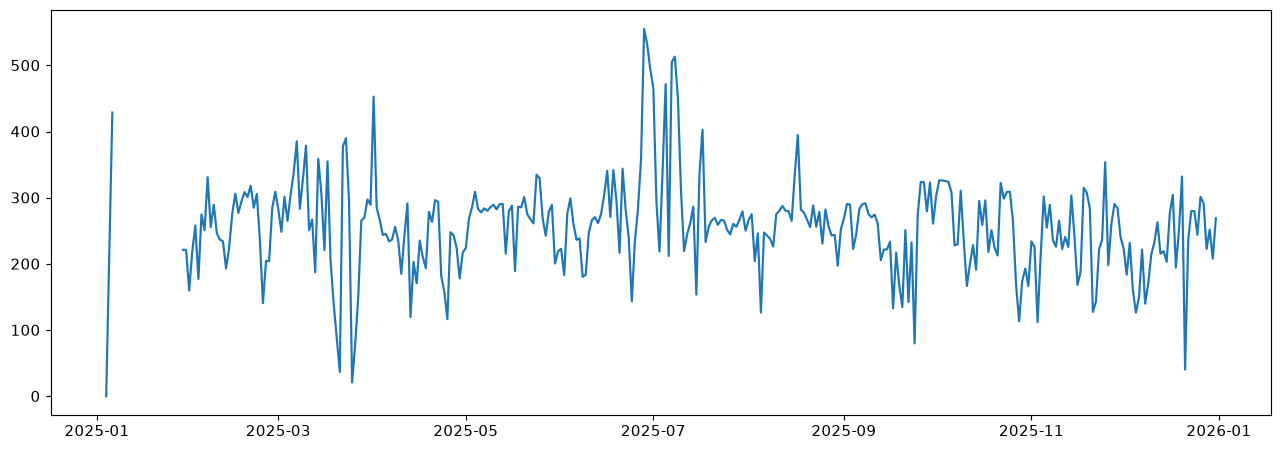

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
plt.plot(df_diario['timestamp'], df_diario['Active_Power'])
plt.show()

## Tratamento diário das lacunas: interpolação e KNN

A base observada acima continua sendo a referência. A partir daqui construímos uma
**versão retrospectiva estimada**, incluindo todos os dias do período, mesmo aqueles
que antes eram removidos por `dropna(how="all")`.

- Meta operacional: no máximo **5% de faltantes por coluna com medições de origem**.
  Esse limite é uma escolha do projeto; não garante precisão da reconstrução.
- Colunas inteiramente ausentes não têm doadores e permanecem `NaN` na versão de
  13 colunas. A exportação de variáveis comuns exclui somente essas três colunas.
- Interpolação temporal linear para lacunas internas de até **2 dias completos**.
  Quando superar o KNN na validação da variável, seu limite aumenta até o maior
  bloco testado (30 dias), sempre sem extrapolar as extremidades.
- KNN ponderado pela distância para as demais lacunas. Os atributos de distância
  são tendência temporal e seno/cosseno do dia do ano, padronizados nos doadores.
  Não usamos potência/energia como entrada para inventar meteorologia.
- O número de vizinhos (3, 5 ou 7) é escolhido com medições artificialmente ocultadas
  em blocos de 1, 7 e 30 dias. A interpolação linear é comparada como referência.

A estratégia se apoia em [Moritz e Bartz-Beielstein (2017)](https://doi.org/10.32614/RJ-2017-009),
[Cho et al. (2020)](https://doi.org/10.1109/BigData50022.2020.9378230) e na
[implementação oficial de KNNImputer](https://scikit-learn.org/stable/modules/generated/sklearn.impute.KNNImputer.html).
As referências, alternativas e limitações estão em `bibliografia_imputacao.md`.

In [7]:
import importlib
import sys
import numpy as np

if str(PASTA_DADOS) not in sys.path:
    sys.path.insert(0, str(PASTA_DADOS))
import imputacao
importlib.reload(imputacao)

META_FALTANTES_PCT = 5.0
LIMITE_LINEAR_DIAS = 2
BLOCOS_VALIDACAO = (1, 7, 30)
COBERTURA_MINIMA_AVALIACAO_PCT = 80.0

df_diario_observado = imputacao.calendario_diario(df_diario)
COLUNAS_COM_DADOS = [c for c in COLUNAS_NUMERICAS if df_diario_observado[c].notna().any()]
COLUNAS_ESTRUTURALMENTE_AUSENTES = [c for c in COLUNAS_NUMERICAS if c not in COLUNAS_COM_DADOS]
resumo_antes = pd.DataFrame({
    "dias_observados": df_diario_observado.notna().sum(),
    "faltantes_antes_pct": 100 * df_diario_observado.isna().mean(),
    "maior_lacuna_dias": [int(imputacao.tamanho_lacunas(df_diario_observado[c]).max()) for c in COLUNAS_NUMERICAS],
})
print(f"Calendário diário completo: {len(df_diario_observado)} dias")
print(f"Colunas com doadores: {len(COLUNAS_COM_DADOS)}; sem qualquer medição: {len(COLUNAS_ESTRUTURALMENTE_AUSENTES)}")
display(resumo_antes)

Calendário diário completo: 363 dias
Colunas com doadores: 9; sem qualquer medição: 3


,dias_observados,faltantes_antes_pct,maior_lacuna_dias
Active_Energy_Delivered_Received,338,6.887052,22
Current_Phase_Average,338,6.887052,22
Active_Power,338,6.887052,22
Wind_Speed,140,61.432507,208
Weather_Temperature_Celsius,140,61.432507,208
Weather_Relative_Humidity,0,100.000000,363
Global_Horizontal_Radiation,140,61.432507,208
Diffuse_Horizontal_Radiation,0,100.000000,363
Wind_Direction,140,61.432507,208
Weather_Daily_Rainfall,140,61.432507,208


In [8]:
df_validacao_detalhada, df_validacao = imputacao.validar_metodos(
    df_diario_observado[COLUNAS_COM_DADOS],
    blocos=BLOCOS_VALIDACAO, repeticoes=4, candidatos=(3, 5, 7), seed=42,
)
# Os resultados são ensaios de reconstrução com contexto dos dois lados da lacuna.
# A média de NRMSE dá o mesmo peso a cada tamanho de bloco na escolha de k.
comparacao_metodos = (
    df_validacao.groupby(["coluna", "metodo"])[["MAE", "RMSE", "NRMSE"]]
    .mean().reset_index()
)
display(comparacao_metodos.pivot(index="coluna", columns="metodo", values="NRMSE"))
print("NRMSE menor indica menor erro relativo neste ensaio; não é garantia para outros períodos.")
print("O bloco real de 208 dias ultrapassa os tamanhos que conseguimos validar.")

NRMSE menor indica menor erro relativo neste ensaio; não é garantia para outros períodos.
O bloco real de 208 dias ultrapassa os tamanhos que conseguimos validar.


metodo,knn_3,knn_5,knn_7,linear
coluna,,,,
Active_Energy_Delivered_Received,0.040980,0.040701,0.040220,0.003975
Active_Power,1.002669,0.970524,0.933834,1.025259
Current_Phase_Average,0.978294,0.902365,0.882889,0.920061
Global_Horizontal_Radiation,0.037789,0.035508,0.035742,0.035490
Radiation_Global_Tilted,0.380176,0.364665,0.354330,0.397002
Weather_Daily_Rainfall,0.969515,1.031152,1.047205,0.884302
Weather_Temperature_Celsius,0.794932,0.739703,0.721468,0.801768
Wind_Direction,0.000000,0.000000,0.000000,0.000000
Wind_Speed,0.714102,0.739582,0.741111,0.664921


### Interpretação da saída

O algoritmo preenche as lacunas possíveis, preservando **todos os valores observados**.
Não reaproveita estimativas como doadores. Cada célula preenchida recebe indicação
no arquivo de auditoria: método, tamanho do bloco ausente e distância em dias até
uma observação. Blocos maiores que 30 dias ficam marcados como `alem_validacao`.
A extensão dessas lacunas não foi validada e continua sendo uma limitação do estudo.

Umidade e as duas radiações difusas permanecem ausentes no CSV de 13 colunas. O CSV
com variáveis comuns tem a mesma informação disponível, excluindo essas colunas;
a taxa de faltantes é reportada separadamente para evitar confundir exclusão com imputação.

Esta é **reconstrução retrospectiva**, que pode usar doadores posteriores à lacuna.
Para prever o futuro, separar treino/teste cronologicamente **antes** de escolher k
ou ajustar escalas e doadores. As funções em `imputacao.py` aceitam `indices_doadores`
para restringir o ajuste aos dias de treino; a validação também precisa ser refeita
em cada partição. Não avaliar um modelo contra potência que foi imputada.
O indicador `avaliacao_potencia_permitida` exige potência observada e cobertura
original de pelo menos 80% dos intervalos; esse limiar é configurável.

In [9]:
df_reconstruido, df_indicadores_imputacao, df_escolhas_imputacao = imputacao.imputar_diario(
    df_diario_observado, df_validacao, limite_linear=LIMITE_LINEAR_DIAS,
)

def contar_metodo(coluna, prefixo):
    return int(df_indicadores_imputacao[f"{coluna}__metodo"].str.startswith(prefixo).sum())

df_relatorio_imputacao = resumo_antes.assign(
    dias_interpolados=[contar_metodo(c, "linear") for c in COLUNAS_NUMERICAS],
    dias_knn=[contar_metodo(c, "knn_") for c in COLUNAS_NUMERICAS],
    faltantes_depois_pct=100 * df_reconstruido.isna().mean(),
    estimados_pct=[100 * df_indicadores_imputacao[f"{c}__imputado"].mean() for c in COLUNAS_NUMERICAS],
    dias_estimados_alem_validacao=[int(df_indicadores_imputacao[f"{c}__alem_validacao"].sum()) for c in COLUNAS_NUMERICAS],
)
qualidade = df_qualidade_diaria.copy()
qualidade.index = qualidade.index.tz_localize(None)
for coluna in ["cobertura_potencia_pct", "cobertura_estacao_pct"]:
    df_indicadores_imputacao[coluna] = qualidade[coluna].reindex(df_reconstruido.index).fillna(0)
df_indicadores_imputacao["potencia_original_observada"] = df_diario_observado["Active_Power"].notna()
df_indicadores_imputacao["avaliacao_potencia_permitida"] = (
    df_indicadores_imputacao["potencia_original_observada"]
    & df_indicadores_imputacao["cobertura_potencia_pct"].ge(COBERTURA_MINIMA_AVALIACAO_PCT)
)

df_diario_imputado = df_reconstruido.reset_index().reindex(columns=COLUNAS_REFERENCIA)
df_diario_comum_imputado = df_diario_imputado[["timestamp", *COLUNAS_COM_DADOS]]
# Asserções verificam calendário, preservação das medições e rastreabilidade.
pd.testing.assert_frame_equal(df_reconstruido.where(df_diario_observado.notna()), df_diario_observado)
assert df_diario_imputado["timestamp"].diff().dropna().eq(pd.Timedelta(days=1)).all()
assert df_reconstruido[COLUNAS_ESTRUTURALMENTE_AUSENTES].isna().all().all()
assert df_relatorio_imputacao.loc[COLUNAS_COM_DADOS, "faltantes_depois_pct"].le(META_FALTANTES_PCT).all()
for coluna in COLUNAS_COM_DADOS:
    assert df_indicadores_imputacao[f"{coluna}__imputado"].equals(
        df_diario_observado[coluna].isna() & df_reconstruido[coluna].notna()
    )

exportacoes = {
    "base_diaria_leopoldo_imputada.csv": df_diario_imputado,
    "base_diaria_leopoldo_comum_imputada.csv": df_diario_comum_imputado,
    "indicadores_imputacao_leopoldo.csv": df_indicadores_imputacao.reset_index(),
    "relatorio_imputacao_leopoldo.csv": df_relatorio_imputacao.rename_axis("coluna").reset_index(),
    "validacao_imputacao_leopoldo.csv": df_validacao,
    "validacao_imputacao_detalhada.csv": df_validacao_detalhada,
    "metodos_imputacao_leopoldo.csv": df_escolhas_imputacao,
}
for nome, base in exportacoes.items():
    base.to_csv(PASTA_DADOS / nome, index=False, date_format="%Y-%m-%d")

taxa_antes = 100 * df_diario_observado[COLUNAS_COM_DADOS].isna().to_numpy().mean()
taxa_depois = 100 * df_reconstruido[COLUNAS_COM_DADOS].isna().to_numpy().mean()
taxa_todas_depois = 100 * df_reconstruido.isna().to_numpy().mean()
print(f"Faltantes nas {len(COLUNAS_COM_DADOS)} variáveis com doadores: {taxa_antes:.2f}% -> {taxa_depois:.2f}%")
print(f"Faltantes considerando as 12 variáveis da referência: {taxa_todas_depois:.2f}% (três colunas sem medições).")
print(f"Dias no resultado final: {len(df_diario_imputado)}")
print(f"Dias com potência original e cobertura >= {COBERTURA_MINIMA_AVALIACAO_PCT:.0f}%: {df_indicadores_imputacao['avaliacao_potencia_permitida'].sum()}")
display(df_relatorio_imputacao.round(3))
display(df_escolhas_imputacao.round(4))
print("Arquivos salvos:", *exportacoes, sep="\n")

Faltantes nas 9 variáveis com doadores: 43.25% -> 0.00%
Faltantes considerando as 12 variáveis da referência: 25.00% (três colunas sem medições).
Dias no resultado final: 363
Dias com potência original e cobertura >= 80%: 271
Arquivos salvos:
base_diaria_leopoldo_imputada.csv
base_diaria_leopoldo_comum_imputada.csv
indicadores_imputacao_leopoldo.csv
relatorio_imputacao_leopoldo.csv
validacao_imputacao_leopoldo.csv
validacao_imputacao_detalhada.csv
metodos_imputacao_leopoldo.csv


,dias_observados,faltantes_antes_pct,maior_lacuna_dias,dias_interpolados,dias_knn,faltantes_depois_pct,estimados_pct,dias_estimados_alem_validacao
Active_Energy_Delivered_Received,338,6.887,22,24,1,0.0,6.887,0
Current_Phase_Average,338,6.887,22,2,23,0.0,6.887,0
Active_Power,338,6.887,22,2,23,0.0,6.887,0
Wind_Speed,140,61.433,208,15,208,0.0,61.433,208
Weather_Temperature_Celsius,140,61.433,208,6,217,0.0,61.433,208
Weather_Relative_Humidity,0,100.000,363,0,0,100.0,0.000,0
Global_Horizontal_Radiation,140,61.433,208,15,208,0.0,61.433,208
Diffuse_Horizontal_Radiation,0,100.000,363,0,0,100.0,0.000,0
Wind_Direction,140,61.433,208,15,208,0.0,61.433,208
Weather_Daily_Rainfall,140,61.433,208,15,208,0.0,61.433,208


,coluna,knn_escolhido,melhor_metodo_validacao,NRMSE_validacao_knn,NRMSE_validacao_linear,limite_linear_aplicado_dias,maior_bloco_validado_dias,dias_lineares,dias_knn
0,Active_Energy_Delivered_Received,knn_7,linear,0.0402,0.0040,30,30,24,1
1,Current_Phase_Average,knn_7,knn_7,0.8829,0.9201,2,30,2,23
2,Active_Power,knn_7,knn_7,0.9338,1.0253,2,30,2,23
3,Wind_Speed,knn_3,linear,0.7141,0.6649,30,30,15,208
4,Weather_Temperature_Celsius,knn_7,knn_7,0.7215,0.8018,2,30,6,217
5,Global_Horizontal_Radiation,knn_5,linear,0.0355,0.0355,30,30,15,208
6,Wind_Direction,knn_3,linear,0.0000,0.0000,30,30,15,208
7,Weather_Daily_Rainfall,knn_3,linear,0.9695,0.8843,30,30,15,208
8,Radiation_Global_Tilted,knn_7,knn_7,0.3543,0.3970,2,30,6,217


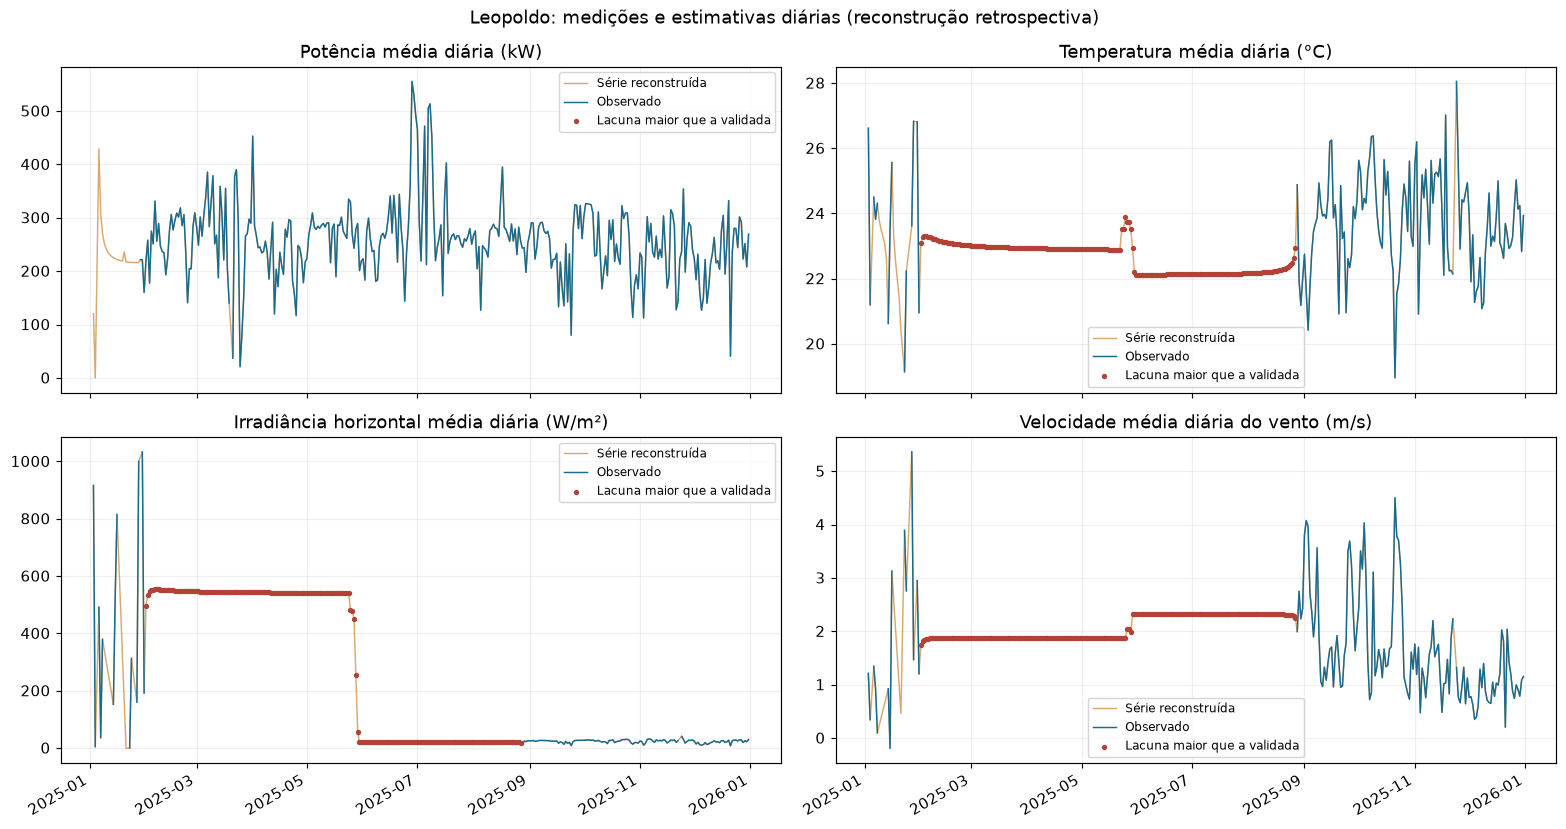

In [10]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 2, figsize=(15, 8), sharex=True)
variaveis_grafico = [
    ("Active_Power", "Potência média diária (kW)"),
    ("Weather_Temperature_Celsius", "Temperatura média diária (°C)"),
    ("Global_Horizontal_Radiation", "Irradiância horizontal média diária (W/m²)"),
    ("Wind_Speed", "Velocidade média diária do vento (m/s)"),
]
for ax, (coluna, titulo) in zip(axes.flat, variaveis_grafico):
    ax.plot(df_reconstruido.index, df_reconstruido[coluna], color="#c67a21", alpha=0.65, linewidth=1, label="Série reconstruída")
    ax.plot(df_diario_observado.index, df_diario_observado[coluna], color="#176b91", linewidth=1, label="Observado")
    fora_validacao = df_indicadores_imputacao[f"{coluna}__alem_validacao"]
    ax.scatter(df_reconstruido.index[fora_validacao], df_reconstruido.loc[fora_validacao, coluna], s=7, color="#b34236", label="Lacuna maior que a validada", zorder=3)
    ax.set_title(titulo)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=8)
fig.suptitle("Leopoldo: medições e estimativas diárias (reconstrução retrospectiva)")
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig(PASTA_DADOS / "diagnostico_imputacao_leopoldo.png", dpi=160, bbox_inches="tight")
plt.show()

## Preenchimento com meteorologia pública da região

Esta etapa substitui o uso de calendário/KNN nas lacunas meteorológicas por séries
horárias do **Copernicus ERA5, disponibilizadas pelo Open-Meteo**. Os dados brutos,
unidades, URL, coordenadas retornadas, data do download e SHA-256 estão em
`dados_publicos/`. O cache permite reproduzir a análise sem baixar novamente.

- Local: latitude **-16,55°**, longitude **-48,85°**, altitude **927 m**.
- Modelo: ERA5 explicitamente selecionado; malha de aproximadamente 0,25°.
  A célula retornada é centrada em -16,50° / -48,75°. É reanálise regional,
  e não observação de um sensor exatamente na usina.
- Horários convertidos em dias de `America/Sao_Paulo`. Chuva e irradiância horárias
  referem-se à hora anterior; o processamento corrige a borda do dia.
- Irradiância em W/m²: média diária de 24 horas, sem confundir com energia diária.
- A coluna de chuva da referência é a média do contador acumulado no dia.
  Reconstruímos esse contador supondo chuva uniforme dentro de cada hora e
  amostragem de 5 minutos. O total diário em mm é exportado em coluna separada.
- Vento a 10 m em m/s; direção agregada com média circular, respeitando 359°/1°.
- Plano dos módulos: inclinação de **20°**, orientação **norte (0°)** como hipótese
  informada na conversa e albedo **0,3** da aba Fixa. Modelo de transposição
  **Perez**, via pvlib. A direção ainda incerta é comparada com 20° e 340°.
  A difusa inclinada inclui componentes do céu e do solo, sem modelar ganho bifacial.

`df_diario_meteo_publica` preserva todas as medições originais e preenche somente
suas lacunas. `df_diario_meteo_homogenea` usa a meteorologia pública durante todo o
período para permitir experimentos sem misturar escalas de sensores/modelos.
A potência e demais variáveis elétricas mantêm o tratamento anterior.

[Documentação da API e unidades](https://open-meteo.com/en/docs/historical-weather-api) ·
[ERA5 — Hersbach et al. (2020)](https://doi.org/10.1002/qj.3803) ·
[Modelo Perez no pvlib](https://pvlib-python.readthedocs.io/en/stable/reference/generated/pvlib.irradiance.get_total_irradiance.html) ·
[Licença e atribuição Open-Meteo — CC BY 4.0](https://open-meteo.com/en/licence).

In [11]:
import json
import meteorologia_publica
importlib.reload(meteorologia_publica)

PASTA_PUBLICOS = PASTA_DADOS / "dados_publicos"
configuracao_usina = json.loads((PASTA_PUBLICOS / "caracteristicas_usina.json").read_text(encoding="utf-8"))
GEOMETRIA_USINA = configuracao_usina if configuracao_usina.get("geometria_habilitada", False) else None
# Margens para completar a hora anterior nas bordas do calendário de 2025.
era5_bruto, metadados_era5 = meteorologia_publica.obter_era5(
    PASTA_PUBLICOS, "2025-01-02", "2026-01-01",
    latitude=configuracao_usina["latitude"], longitude=configuracao_usina["longitude"],
    altitude=configuracao_usina["altitude_m"],
)
df_era5_horario, df_era5_diario = meteorologia_publica.agregar_era5(
    era5_bruto, df_diario_observado.index.min(), df_diario_observado.index.max(),
    geometria=GEOMETRIA_USINA,
)
print("Local solicitado:", configuracao_usina["latitude"], configuracao_usina["longitude"], configuracao_usina["altitude_m"], "m")
print("Célula retornada:", metadados_era5["resposta_localizacao"])
print(f"Série bruta: {len(df_era5_horario)} horas; série diária: {len(df_era5_diario)} dias.")
print("Geometria adotada como hipótese:", GEOMETRIA_USINA is not None)
display(df_era5_diario.head())

Local solicitado: -16.55 -48.85 927 m
Célula retornada: {'latitude': -16.5, 'longitude': -48.75, 'elevation': 927.0, 'timezone': 'America/Sao_Paulo', 'utc_offset_seconds': -10800}
Série bruta: 8760 horas; série diária: 363 dias.
Geometria adotada como hipótese: True


,Weather_Temperature_Celsius,Weather_Relative_Humidity,Wind_Speed,Wind_Direction,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Weather_Daily_Rainfall,Rainfall_Total_mm,GHI_Energy_kWh_m2,Direct_Normal_Radiation,Public_Weather_Hours,Public_Radiation_Hours,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
timestamp,,,,,,,,,,,,,,
2025-01-03,23.375000,76.375000,2.343750,284.396184,268.708333,76.083333,0.201215,0.5,6.449,265.337500,24,24,239.485422,74.903259
2025-01-04,23.054167,80.000000,1.552500,274.848980,277.541667,74.458333,2.729514,9.4,6.661,271.954167,24,24,247.894589,73.392988
2025-01-05,22.820833,84.125000,1.872083,7.266863,219.500000,94.625000,4.951910,12.1,5.268,165.062500,24,24,199.805786,91.999549
2025-01-06,22.358333,85.666667,2.092500,324.012886,174.541667,108.375000,4.592187,8.1,4.189,107.504167,24,24,158.299538,103.957247
2025-01-07,23.554167,80.125000,2.384167,320.555359,268.541667,94.708333,0.669097,3.4,6.445,250.054167,24,24,240.094395,92.493081


In [12]:
# Comparar somente dias com pelo menos 80% dos registros originais da estação.
df_comparacao_era5 = meteorologia_publica.comparar_com_estacao(
    df_diario_observado, df_era5_diario,
    cobertura=df_indicadores_imputacao["cobertura_estacao_pct"], cobertura_minima=80,
)
display(df_comparacao_era5.round(3))
if df_comparacao_era5["escala_a_revisar"].any():
    print("Revisar escala/unidade dos sensores:", df_comparacao_era5.loc[df_comparacao_era5.escala_a_revisar, "coluna"].tolist())
print("Não corrigimos automaticamente o viés para coincidir com uma medição possivelmente inconsistente.")
print("A direção observada é constante em 360°; sua correlação não é informativa.")

Revisar escala/unidade dos sensores: ['Global_Horizontal_Radiation']
Não corrigimos automaticamente o viés para coincidir com uma medição possivelmente inconsistente.
A direção observada é constante em 360°; sua correlação não é informativa.


,coluna,dias_comparados,MAE,RMSE,vies_publico_menos_estacao,correlacao,mediana_estacao,mediana_publica,razao_mediana_publico_estacao,estacao_constante,escala_a_revisar
0,Wind_Speed,109,0.773,0.968,0.760,0.794,1.414,2.209,1.562,False,False
1,Weather_Temperature_Celsius,109,0.687,0.887,0.529,0.896,23.848,24.433,1.025,False,False
2,Global_Horizontal_Radiation,109,234.406,239.493,234.406,0.749,24.805,265.500,10.704,False,True
3,Wind_Direction,109,80.713,91.970,40.283,NaN,360.000,102.961,0.286,True,False
4,Weather_Daily_Rainfall,109,1.146,2.412,1.129,0.266,0.000,0.056,NaN,False,False
5,Radiation_Global_Tilted,109,37.113,48.898,11.332,0.719,242.441,263.436,1.087,False,False


In [13]:
df_publica, df_origens_publica, df_relatorio_publica = meteorologia_publica.preencher_com_publicos(
    df_diario_observado, df_era5_diario, eletrico_estimado=df_reconstruido,
)
for coluna in ["cobertura_potencia_pct", "cobertura_estacao_pct", "avaliacao_potencia_permitida"]:
    df_origens_publica[coluna] = df_indicadores_imputacao[coluna]
for coluna in COLUNAS_ELETRICAS:
    df_origens_publica[f"{coluna}__metodo_eletrico"] = df_indicadores_imputacao[f"{coluna}__metodo"]
COLUNAS_METEO_PUBLICAS = [c for c in COLUNAS_NUMERICAS if c not in COLUNAS_ELETRICAS and c in df_era5_diario]
# Variante de meteorologia homogênea: mantém os valores elétricos e usa uma fonte
# meteorológica durante todo o período. As medições continuam na base observada.
df_homogenea = df_publica.copy()
df_homogenea[COLUNAS_METEO_PUBLICAS] = df_era5_diario[COLUNAS_METEO_PUBLICAS]
df_diario_meteo_publica = df_publica.reset_index().reindex(columns=COLUNAS_REFERENCIA)
df_diario_meteo_homogenea = df_homogenea.reset_index().reindex(columns=COLUNAS_REFERENCIA)

pd.testing.assert_frame_equal(df_publica.where(df_diario_observado.notna()), df_diario_observado)
assert df_diario_meteo_publica.columns.tolist() == COLUNAS_REFERENCIA
assert df_era5_diario["Public_Weather_Hours"].eq(24).all()
assert df_era5_diario["Public_Radiation_Hours"].eq(24).all()
assert not df_era5_diario[COLUNAS_METEO_PUBLICAS].isna().any().any()
assert not df_origens_publica.loc[df_diario_observado["Active_Power"].isna(), "avaliacao_potencia_permitida"].any()

exportacoes_publicas = {
    "meteorologia_era5_diaria.csv": df_era5_diario.reset_index(),
    "base_diaria_leopoldo_meteo_publica.csv": df_diario_meteo_publica,
    "base_diaria_leopoldo_meteo_homogenea.csv": df_diario_meteo_homogenea,
    "origens_meteorologia_publica.csv": df_origens_publica.reset_index(),
    "relatorio_meteorologia_publica.csv": df_relatorio_publica,
    "comparacao_era5_estacao.csv": df_comparacao_era5,
}
for nome, base in exportacoes_publicas.items():
    base.to_csv(PASTA_DADOS / nome, index=False, date_format="%Y-%m-%d")
df_era5_horario.reset_index().to_csv(PASTA_PUBLICOS / "meteorologia_era5_horaria.csv", index=False)
resumo_processamento = {
    "fonte": "Copernicus ERA5 / Open-Meteo", "url": metadados_era5["url"],
    "sha256_bruto": metadados_era5["sha256"],
    "geometria": configuracao_usina,
    "dias": len(df_publica), "colunas_meteorologicas": COLUNAS_METEO_PUBLICAS,
    "faltantes_finais_pct": float(100 * df_publica.isna().to_numpy().mean()),
    "regra_chuva": "Média do acumulado diário em pontos de 5 min, com chuva uniforme dentro da hora; total separado.",
    "regra_poa": "Perez no meio da hora; albedo 0,3; sem ganho bifacial nem sombreamento de horizonte.",
    "licenca": "https://open-meteo.com/en/licence",
}
(PASTA_PUBLICOS / "processamento_meteorologia.json").write_text(json.dumps(resumo_processamento, ensure_ascii=False, indent=2) + "\n", encoding="utf-8")
print(f"Resultado: {len(df_publica)} dias, {len(COLUNAS_REFERENCIA)} colunas, {100 * df_publica.isna().to_numpy().mean():.2f}% de faltantes.")
print("Preenchimentos com ERA5/Perez:", int(df_relatorio_publica.dias_ERA5.sum()))
print("Arquivos finais: base_diaria_leopoldo_meteo_publica.csv e base_diaria_leopoldo_meteo_homogenea.csv")
display(df_relatorio_publica.round(3))

Resultado: 363 dias, 13 colunas, 0.00% de faltantes.
Preenchimentos com ERA5/Perez: 2427
Arquivos finais: base_diaria_leopoldo_meteo_publica.csv e base_diaria_leopoldo_meteo_homogenea.csv


,coluna,dias_observados,dias_ERA5,dias_imputacao_eletrica,faltantes_antes_pct,faltantes_depois_pct
0,Active_Energy_Delivered_Received,338,0,25,6.887,0.0
1,Current_Phase_Average,338,0,25,6.887,0.0
2,Active_Power,338,0,25,6.887,0.0
3,Wind_Speed,140,223,0,61.433,0.0
4,Weather_Temperature_Celsius,140,223,0,61.433,0.0
5,Weather_Relative_Humidity,0,363,0,100.000,0.0
6,Global_Horizontal_Radiation,140,223,0,61.433,0.0
7,Diffuse_Horizontal_Radiation,0,363,0,100.000,0.0
8,Wind_Direction,140,223,0,61.433,0.0
9,Weather_Daily_Rainfall,140,223,0,61.433,0.0


In [14]:
sensibilidade = []
if GEOMETRIA_USINA is not None:
    referencia_poa = df_era5_diario["Radiation_Global_Tilted"]
    for azimute in (0, 20, 340):
        if azimute == 0:
            serie_poa = referencia_poa
        else:
            alternativa = dict(GEOMETRIA_USINA, azimute_norte_horario_graus=azimute)
            _, serie_alternativa = meteorologia_publica.agregar_era5(
                era5_bruto, df_diario_observado.index.min(), df_diario_observado.index.max(), alternativa,
            )
            serie_poa = serie_alternativa["Radiation_Global_Tilted"]
        diferenca = 100 * (serie_poa / referencia_poa - 1)
        sensibilidade.append({
            "azimute_norte_horario_graus": azimute, "inclinacao_graus": 20,
            "variacao_energia_periodo_pct": 100 * (serie_poa.sum() / referencia_poa.sum() - 1),
            "max_variacao_diaria_absoluta_pct": float(diferenca.abs().max()),
        })
df_sensibilidade_azimute = pd.DataFrame(sensibilidade)
df_sensibilidade_azimute.to_csv(PASTA_DADOS / "sensibilidade_azimute_era5.csv", index=False)
display(df_sensibilidade_azimute.round(3))

,azimute_norte_horario_graus,inclinacao_graus,variacao_energia_periodo_pct,max_variacao_diaria_absoluta_pct
0,0,20,0.000,0.000
1,20,20,0.061,6.298
2,340,20,-1.001,6.646


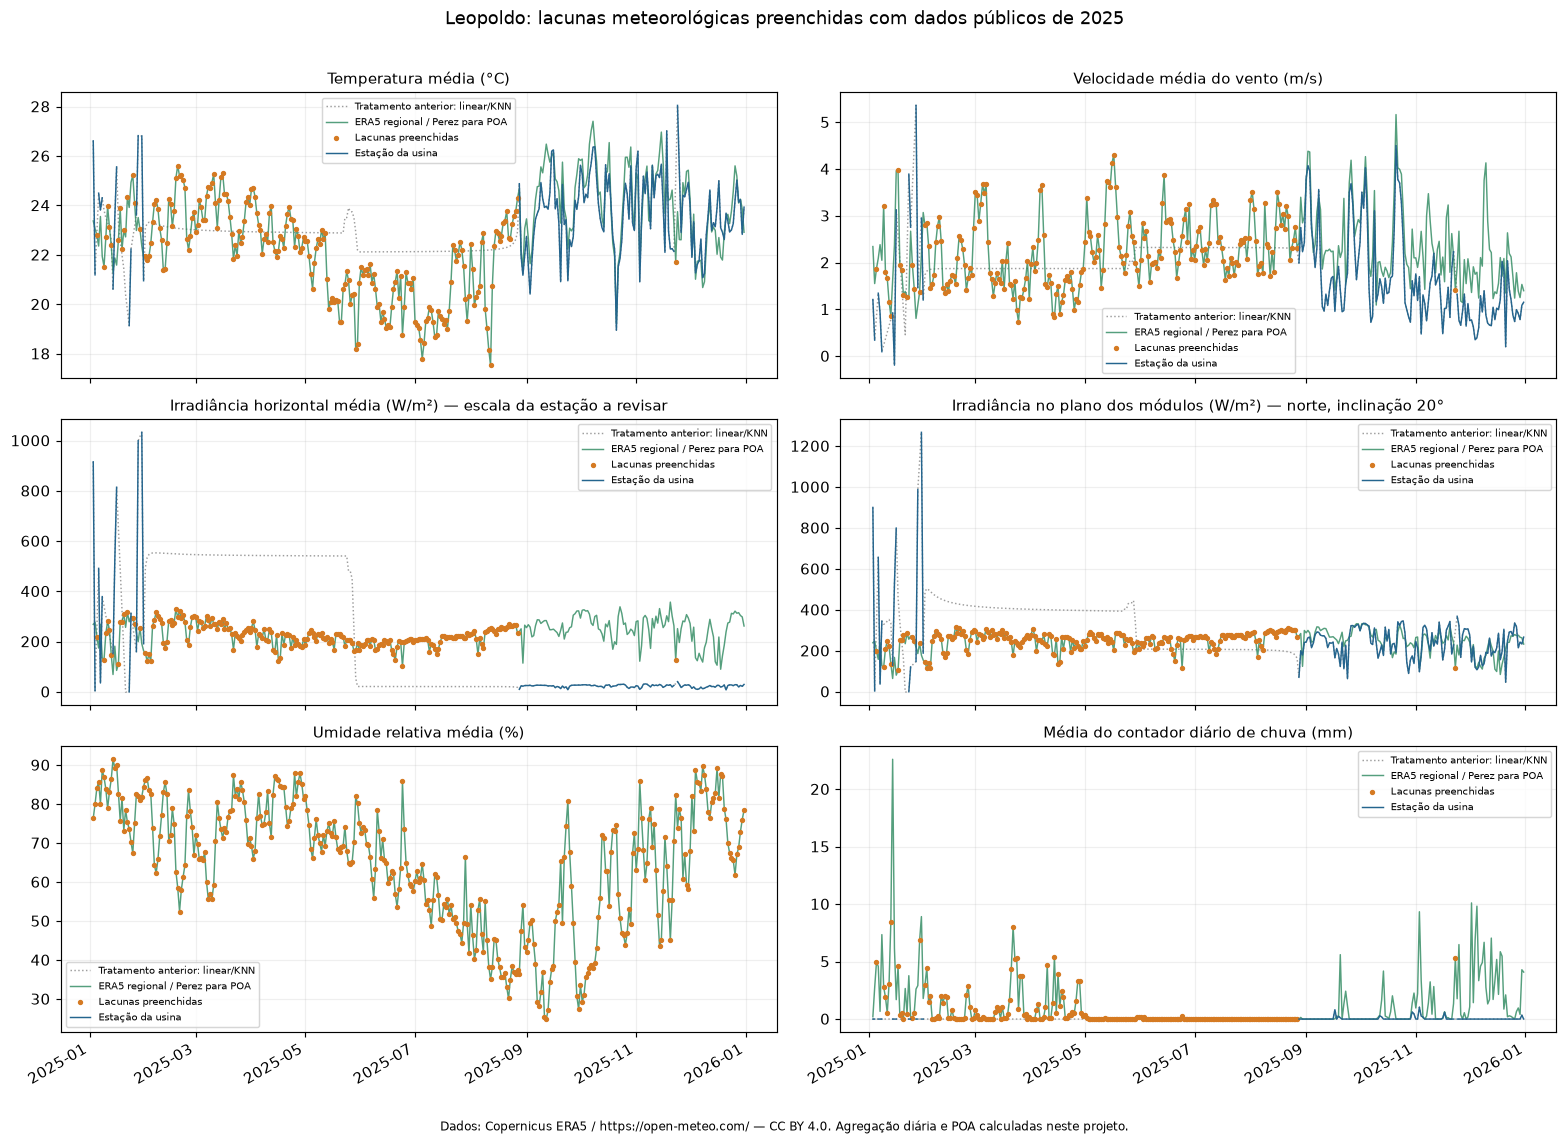

In [15]:
fig, axes = plt.subplots(3, 2, figsize=(15, 11), sharex=True)
variaveis_publicas = [
    ("Weather_Temperature_Celsius", "Temperatura média (°C)"),
    ("Wind_Speed", "Velocidade média do vento (m/s)"),
    ("Global_Horizontal_Radiation", "Irradiância horizontal média (W/m²) — escala da estação a revisar"),
    ("Radiation_Global_Tilted", "Irradiância no plano dos módulos (W/m²) — norte, inclinação 20°"),
    ("Weather_Relative_Humidity", "Umidade relativa média (%)"),
    ("Weather_Daily_Rainfall", "Média do contador diário de chuva (mm)"),
]
for ax, (coluna, titulo) in zip(axes.flat, variaveis_publicas):
    ax.plot(df_reconstruido.index, df_reconstruido[coluna], color="#9c9c9c", linestyle=":", linewidth=1, label="Tratamento anterior: linear/KNN")
    ax.plot(df_era5_diario.index, df_era5_diario[coluna], color="#2b875d", linewidth=1, alpha=0.8, label="ERA5 regional / Perez para POA")
    estimados = df_diario_observado[coluna].isna() & df_publica[coluna].notna()
    ax.scatter(df_publica.index[estimados], df_publica.loc[estimados, coluna], color="#d57a22", s=7, label="Lacunas preenchidas", zorder=3)
    ax.plot(df_diario_observado.index, df_diario_observado[coluna], color="#24658e", linewidth=1, label="Estação da usina", zorder=4)
    ax.set_title(titulo, fontsize=10)
    ax.grid(alpha=0.2)
    ax.legend(fontsize=7, loc="best")
fig.suptitle("Leopoldo: lacunas meteorológicas preenchidas com dados públicos de 2025")
fig.autofmt_xdate()
fig.tight_layout(rect=[0, 0.035, 1, 0.97])
fig.text(0.5, 0.01, "Dados: Copernicus ERA5 / https://open-meteo.com/ — CC BY 4.0. Agregação diária e POA calculadas neste projeto.", ha="center", fontsize=8)
fig.savefig(PASTA_DADOS / "diagnostico_meteorologia_publica.png", dpi=150, bbox_inches="tight")
plt.show()

## Auditoria dos arquivos originais: faltantes por dia e alternativas

Esta seção conta os horários ausentes **antes de qualquer imputação**, no calendário completo de 2025 (365 dias). São esperados 288 registros da estação e 2.304 leituras dos oito inversores por dia. O cenário por identidade considera `meta.id_usina=50`, os oito IDs e seus números de série, incluindo os códigos textuais `07-07FX` e `07-07TK-2` do mesmo equipamento. O cenário anterior, restrito a `07-07FX`, é preservado para comparação.

**Resultado:** 26 dias recuperados com observações reais pelo critério de identidade; somente 20/03/2025 continua sem nenhum intervalo completo de potência. Isso não torna os outros dias completos. Na estação há 225 dias sem qualquer registro, incluindo o bloco de 208 dias entre 01/02 e 27/08. Janeiro tem apenas 62 horários únicos da estação.

As bases e etapas anteriores continuam como estavam para comparação. Esta auditoria não promove automaticamente as novas alternativas para a modelagem. O relatório [análise e estratégia](auditoria_original/analise_e_estrategia.md) explica as limitações e a recomendação.


In [16]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import display, Image

PASTA_AUDITORIA_DADOS = Path.cwd() / "leopoldo"
if not (PASTA_AUDITORIA_DADOS / "Leopoldo-fixa-inv.csv").exists():
    PASTA_AUDITORIA_DADOS = Path.cwd()
PASTA_AUDITORIA = PASTA_AUDITORIA_DADOS / "auditoria_original"
if not (PASTA_AUDITORIA / "resumo_por_dia.csv").exists():
    if str(PASTA_AUDITORIA_DADOS) not in sys.path:
        sys.path.insert(0, str(PASTA_AUDITORIA_DADOS))
    from auditoria_base_original import executar_auditoria
    executar_auditoria(PASTA_AUDITORIA_DADOS)
# Para atualizar a auditoria após mudar os CSVs:
# from auditoria_base_original import executar_auditoria
# executar_auditoria(PASTA_AUDITORIA_DADOS)

df_faltantes_por_dia = pd.read_csv(PASTA_AUDITORIA / "resumo_por_dia.csv", parse_dates=["timestamp"]).set_index("timestamp")
df_faltantes_detalhados = pd.read_csv(PASTA_AUDITORIA / "faltantes_por_dia.csv", parse_dates=["timestamp"]).set_index("timestamp")
df_faltantes_mensais = pd.read_csv(PASTA_AUDITORIA / "resumo_mensal.csv", index_col=0)
df_cobertura_auditoria = pd.read_csv(PASTA_AUDITORIA / "cobertura_por_limiar.csv")
df_validacao_5min = pd.read_csv(PASTA_AUDITORIA / "validacao_lacunas_curtas.csv")
print(f"Contagem de cada dia disponível em df_faltantes_por_dia: {len(df_faltantes_por_dia)} dias.")
print("Primeiros 10 dias; o CSV contém o ano completo:")
display(df_faltantes_por_dia.head(10).round(2))
print("Resumo mensal — cenário por identidade dos equipamentos:")
display(df_faltantes_mensais.round(2))


Contagem de cada dia disponível em df_faltantes_por_dia: 365 dias.
Primeiros 10 dias; o CSV contém o ano completo:
Resumo mensal — cenário por identidade dos equipamentos:


,estacao_registros_presentes,estacao_registros_ausentes,estacao_faltantes_pct,inversores_potencias_validas,inversores_potencias_faltantes_total,planta_intervalos_completos,planta_intervalos_faltantes,planta_diurnos_faltantes,planta_noturnos_faltantes,planta_cobertura_diurna_pct,intervalos_recuperados_por_identidade,planta_intervalos_recuperaveis_linear15,estacao_pontos_recuperaveis_linear15
timestamp,,,,,,,,,,,,,
2025-01-01,0,288,100.00,2155,149,266,22,6,16,96.18,266,10,0
2025-01-02,0,288,100.00,2152,152,267,21,6,15,96.18,267,10,0
2025-01-03,1,287,99.65,2022,282,249,39,25,14,84.08,249,13,0
2025-01-04,6,282,97.92,2158,146,267,21,8,13,94.90,264,10,1
2025-01-05,0,288,100.00,2130,174,263,25,11,14,92.95,263,14,0
2025-01-06,42,246,85.42,2115,189,262,26,14,12,91.03,231,15,1
2025-01-07,1,287,99.65,2117,187,264,24,9,15,94.23,264,13,0
2025-01-08,1,287,99.65,2125,179,263,25,7,18,95.51,263,14,0
2025-01-09,0,288,100.00,2154,150,267,21,7,14,95.51,267,6,0


,dias,dias_sem_potencia,dias_sem_estacao,faltantes_estacao,faltantes_potencia_planta,recuperaveis_linear15,recuperados_por_identidade,cobertura_media_diurna_pct
mes,,,,,,,,
2025-01,31,0,16,8866,1036,312,7236,93.43
2025-02,28,0,28,8064,627,70,0,98.77
2025-03,31,1,31,8928,2553,110,0,78.31
2025-04,30,0,30,8640,481,54,0,95.71
2025-05,31,0,31,8928,1664,841,0,86.26
2025-06,30,0,30,8640,2122,888,0,87.59
2025-07,31,0,31,8928,2227,647,0,86.79
2025-08,31,0,27,7975,868,614,0,90.18
2025-09,30,0,0,284,647,499,0,91.26


### O que pode ser recuperado e com qual evidência

A simulação linear preenche somente blocos internos inteiros de até três amostras ausentes (15 minutos), por inversor, com extremos no mesmo dia. Recuperaria 5.353 intervalos completos da planta, mas apenas 597 da estação. Não preenche o semestre sem meteorologia. Os limiares abaixo são escolhas operacionais para análise de sensibilidade, não normas de qualidade.

Na validação, foram ocultados blocos medidos de **um inversor por vez**, com os outros sete disponíveis. O proxy usa a soma contemporânea dos sete, escalada pela razão mediana nos 30 dias anteriores; a interpolação linear usa os extremos. Os dois métodos são comparados nos mesmos casos. O RMSE refere-se a um inversor de 125 kW. Esse teste não valida lacunas simultâneas dos oito, dias inteiros nem meses sem estação. Os blocos podem se sobrepor; são métricas descritivas.

**Estratégia preferida:** recuperar observações por identidade → controlar falhas → reconstruir pequenas lacunas em cinco minutos → agregar com cobertura diária → usar meteorologia externa homogênea para o ano. Manter 20 de março fora da avaliação de alvos observados. Não buscar 0% de faltantes como critério de sucesso.

A diferença dos contadores de energia fornece uma alternativa de alvo em 309 dias, ainda sujeita à validação de resets e coerência com a integral de potência. Média das amostras presentes não equivale necessariamente à média de 24 horas. A comparação entre Brasil e Austrália deve manter a mesma definição de alvo e unidades.


In [17]:
print("Validação de lacunas curtas — erro por inversor, em kW:")
display(df_validacao_5min.round(2))
print("Dias disponíveis por cobertura mínima — antes e após simulação linear:")
display(df_cobertura_auditoria.loc[df_cobertura_auditoria.cenario.eq("identidade")])
print("Dias com menor cobertura diurna observada de potência:")
display(df_faltantes_por_dia.sort_values("planta_cobertura_diurna_pct").head(10).round(2))


Validação de lacunas curtas — erro por inversor, em kW:
Dias disponíveis por cobertura mínima — antes e após simulação linear:
Dias com menor cobertura diurna observada de potência:


,metodo,lacuna_minutos,casos,pontos,MAE_kw,RMSE_kw,erro_absoluto_p95_kw,NRMSE_potencia_nominal_125kw_pct
0,linear_temporal,5,180,180,7.75,15.73,43.69,12.58
1,linear_temporal,10,179,358,9.24,20.62,51.33,16.49
2,linear_temporal,15,179,537,9.48,19.67,49.12,15.73
3,outros_7_inversores,5,180,180,3.54,6.73,10.50,5.38
4,outros_7_inversores,10,179,358,3.14,5.72,10.20,4.58
5,outros_7_inversores,15,179,537,3.99,7.66,13.91,6.13


,cenario,cobertura_minima_pct,dias_cobertura_24h,dias_cobertura_diurna,dias_diurna_poslinear15,dias_com_estacao_e_potencia_diurnas,dias_conjuntos_poslinear15
7,identidade,50,344,357,358,123,123
8,identidade,75,303,331,338,110,111
9,identidade,80,295,326,334,109,110
10,identidade,90,230,241,314,98,104
11,identidade,95,73,118,298,25,98
12,identidade,99,6,48,284,0,97
13,identidade,100,4,30,280,0,97


,estacao_registros_presentes,estacao_registros_ausentes,estacao_faltantes_pct,inversores_potencias_validas,inversores_potencias_faltantes_total,planta_intervalos_completos,planta_intervalos_faltantes,planta_diurnos_faltantes,planta_noturnos_faltantes,planta_cobertura_diurna_pct,intervalos_recuperados_por_identidade,planta_intervalos_recuperaveis_linear15,estacao_pontos_recuperaveis_linear15
timestamp,,,,,,,,,,,,,
2025-03-20,0,288,100.00,0,2304,0,288,144,144,0.00,0,0,0
2025-03-21,0,288,100.00,731,1573,89,199,122,77,15.28,0,1,0
2025-12-21,100,188,65.28,768,1536,96,192,119,73,24.20,0,6,2
2025-03-19,0,288,100.00,946,1358,111,177,102,75,29.66,0,4,0
2025-03-25,0,288,100.00,892,1412,109,179,99,80,31.25,0,18,0
2025-07-15,0,288,100.00,951,1353,112,176,88,88,34.33,0,10,0
2025-03-16,0,288,100.00,990,1314,120,168,90,78,37.93,0,1,0
2025-05-24,0,288,100.00,909,1395,112,176,71,105,47.01,0,44,0
2025-03-23,0,288,100.00,603,1701,75,213,69,144,52.08,0,23,0


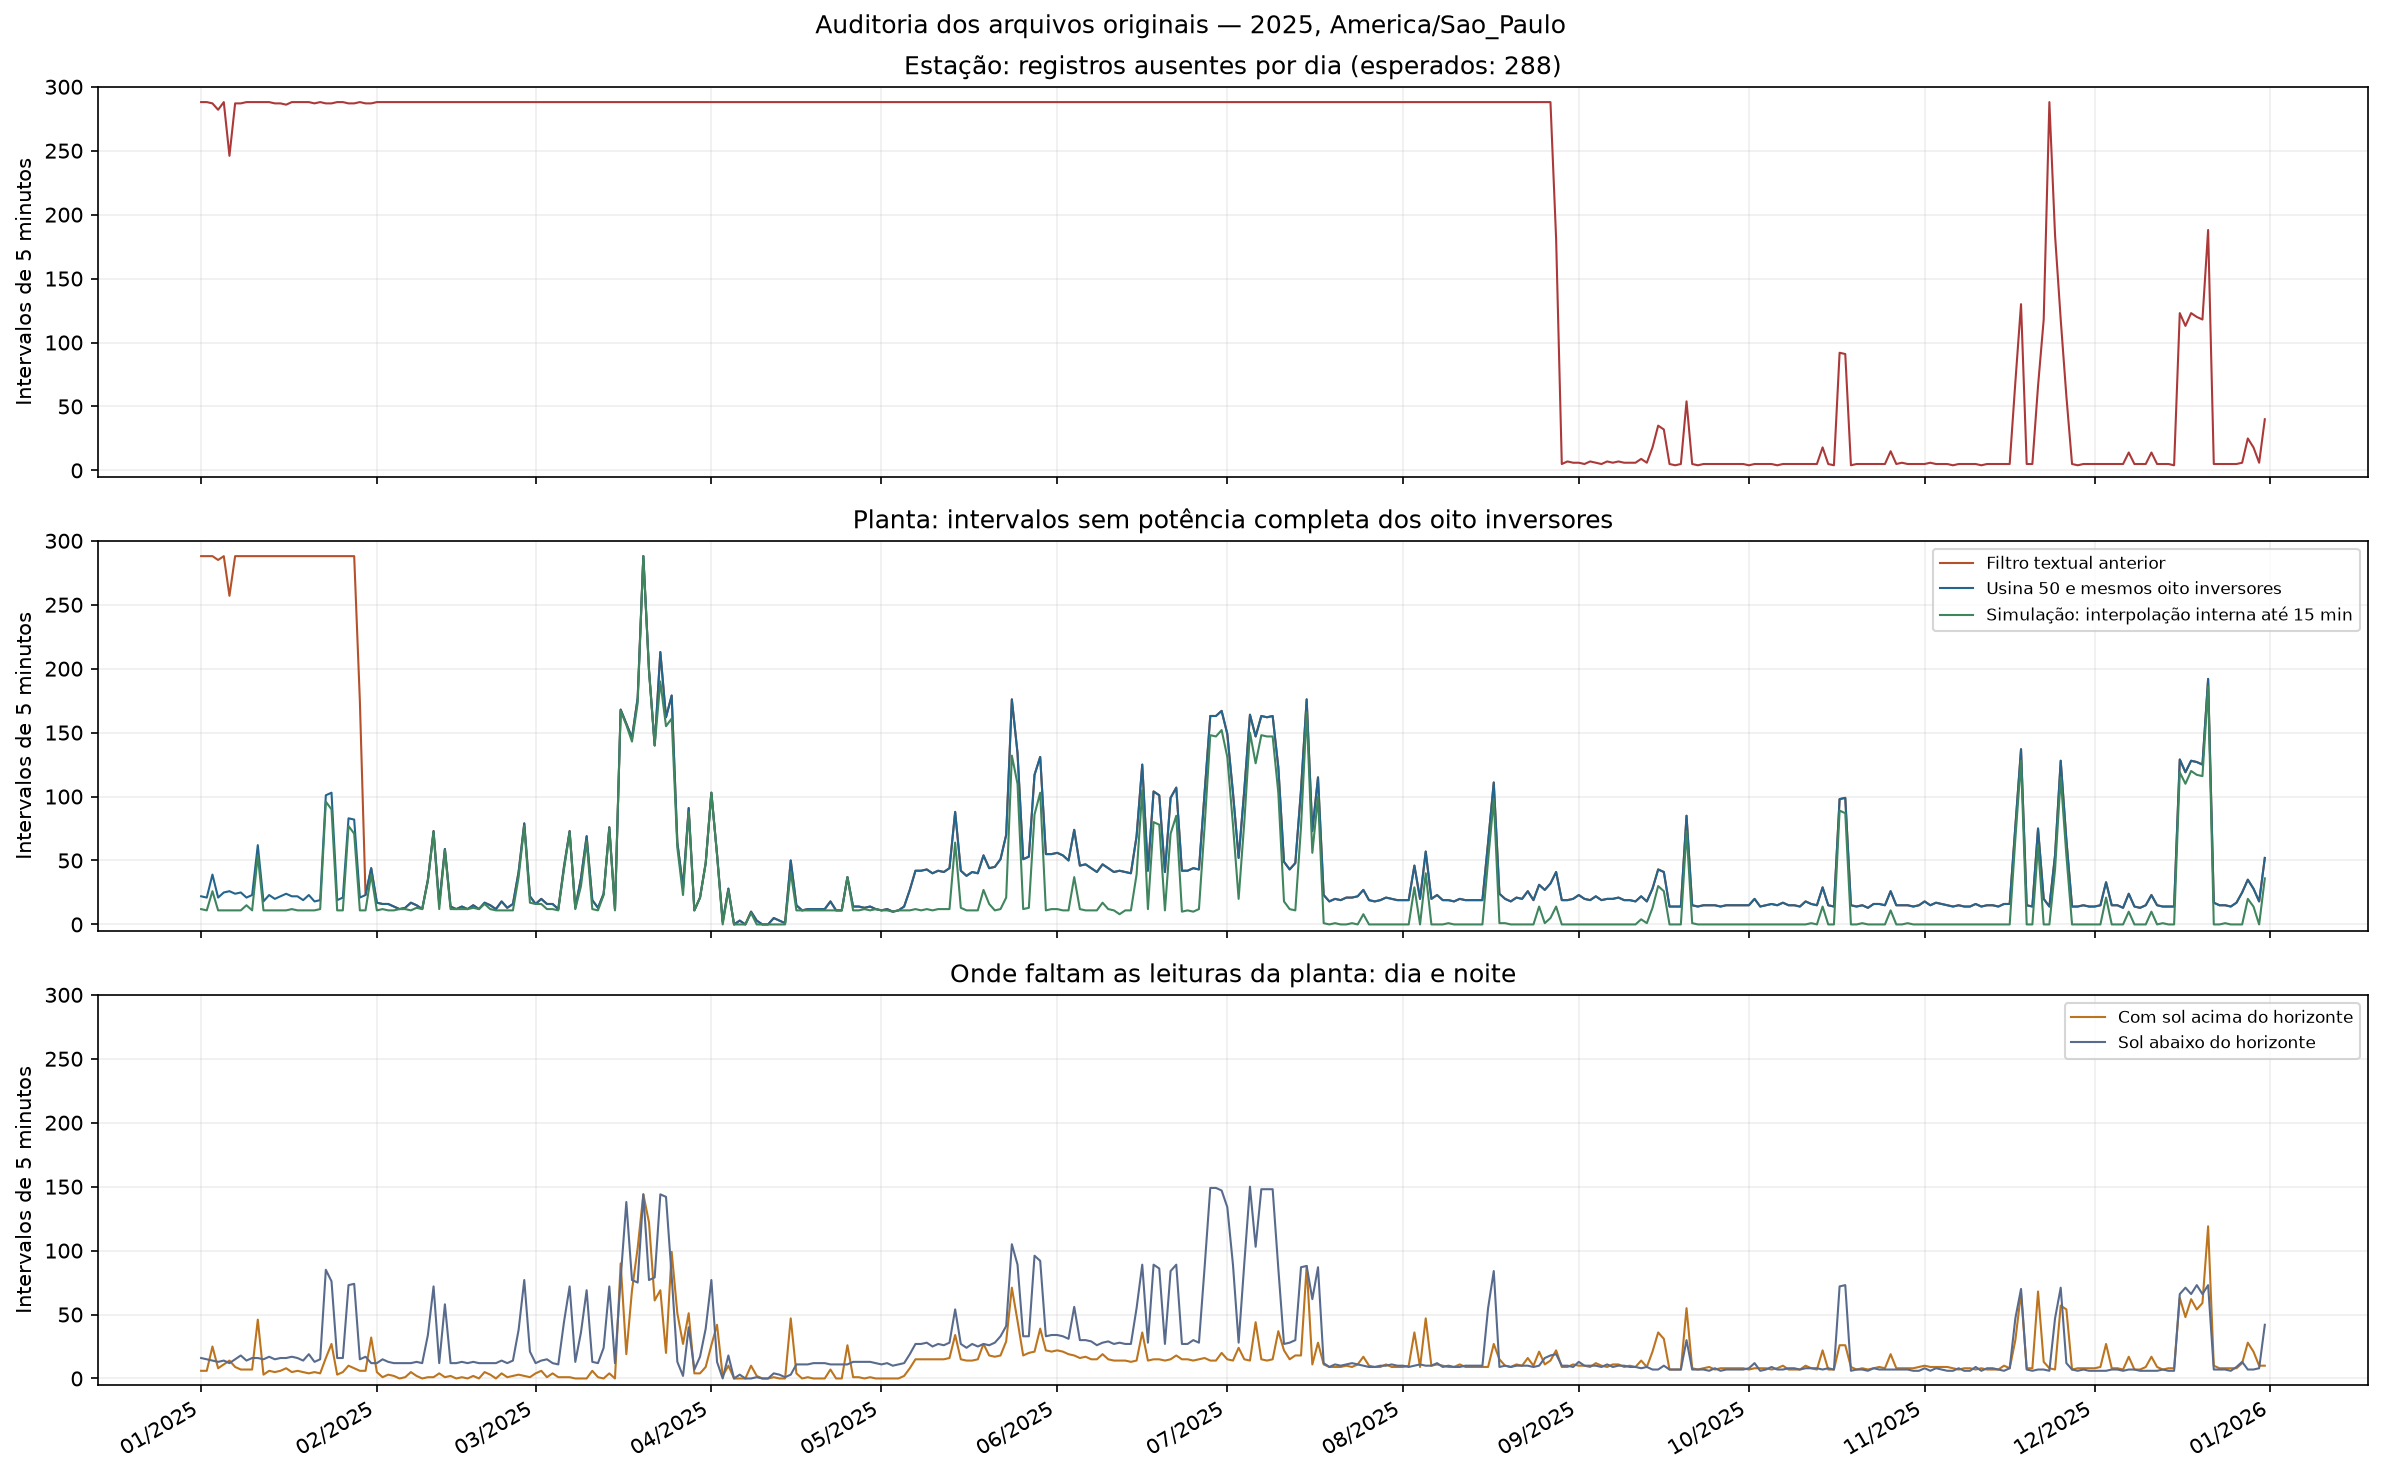

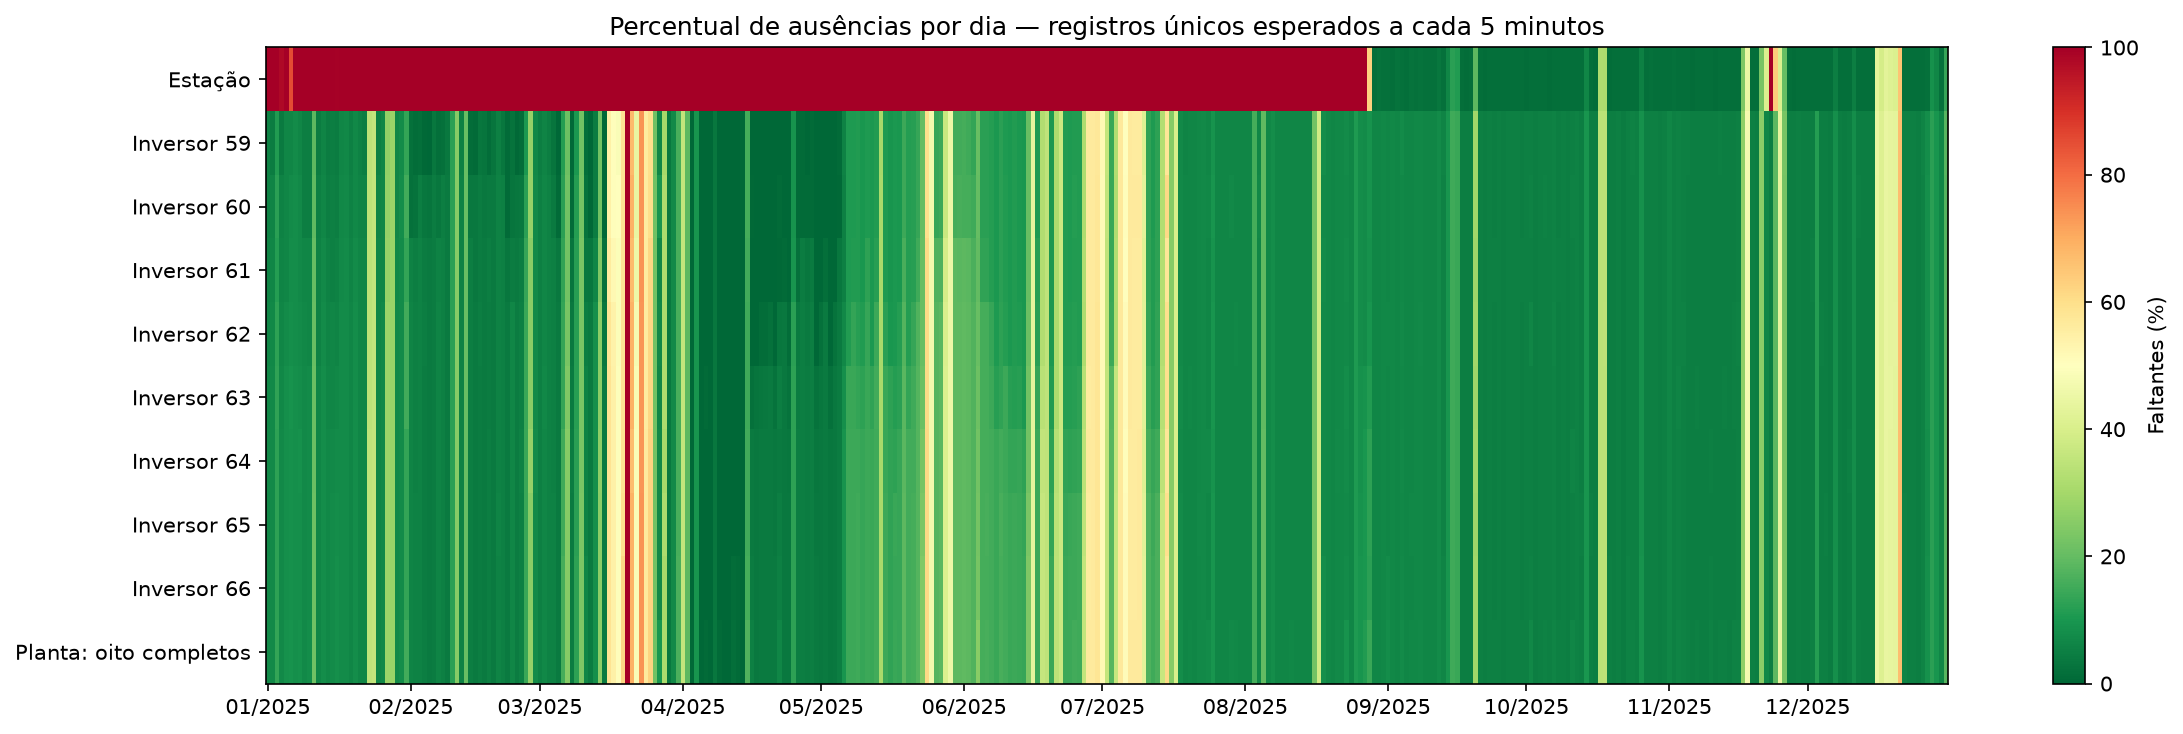

In [18]:
display(Image(filename=str(PASTA_AUDITORIA / "faltantes_originais_por_dia.png")))
display(Image(filename=str(PASTA_AUDITORIA / "mapa_faltantes_originais.png")))


## Base diária selecionada: maior bloco consecutivo aprovado

Esta é a saída recomendada da estratégia atual. O processamento usa os mesmos oito inversores identificados por ID e número de série, trata lacunas na resolução de cinco minutos e usa meteorologia ERA5 homogênea. A seleção exige **pelo menos 95% de cobertura da potência completa no período diurno e nas 24 horas**, todas as colunas diárias finitas e alguma potência completa originalmente medida. Dias reprovados interrompem o bloco: não são removidos para juntar artificialmente os períodos.

A base final conserva as 13 colunas e a ordem da Austrália. Não há datas ausentes nem células vazias no bloco selecionado; isso não significa que todas as amostras de cinco minutos sejam medidas ou preenchidas. Consulte a cobertura e a fração imputada na tabela de qualidade. O alvo é a média diária de potência em kW, não energia em kWh.

[Base selecionada](base_diaria_leopoldo_consecutiva.csv) · [Relatório e gráfico](base_consecutiva.md) · [Todos os blocos aprovados](blocos_consecutivos_leopoldo.csv)


In [19]:
from pathlib import Path
import sys
import importlib
import pandas as pd
from IPython.display import display, Image

PASTA_BASE_CONSECUTIVA = next(
    p / "leopoldo" for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "leopoldo" / "Leopoldo-fixa-inv.csv").is_file()
)
if str(PASTA_BASE_CONSECUTIVA) not in sys.path:
    sys.path.insert(0, str(PASTA_BASE_CONSECUTIVA))
import base_consecutiva
importlib.reload(base_consecutiva)
resultado_base_consecutiva = base_consecutiva.gerar_base(PASTA_BASE_CONSECUTIVA)
df_base_diaria_final = resultado_base_consecutiva["base"]
df_qualidade_base_final = resultado_base_consecutiva["qualidade"]
df_blocos_aprovados = resultado_base_consecutiva["blocos"]
resumo_base_final = resultado_base_consecutiva["resumo"]
print(f"Base final: {resumo_base_final['inicio']} a {resumo_base_final['fim']}")
print(f"{len(df_base_diaria_final)} dias consecutivos; {df_base_diaria_final.shape[1]} colunas; {int(df_base_diaria_final.isna().sum().sum())} valores ausentes.")
print(f"No ano: {resumo_base_final['dias_elegiveis_ano']} dias aprovados, em {resumo_base_final['blocos_elegiveis']} blocos separados.")
print(f"Menor cobertura diurna tratada do bloco: {resumo_base_final['menor_cobertura_diurna_selecionada_pct']:.2f}%")
print(f"Maior fração diurna com alguma estimativa: {resumo_base_final['maior_fracao_diurna_estimada_selecionada_pct']:.2f}%")


Base final: 2025-02-01 a 2025-03-15
43 dias consecutivos; 13 colunas; 0 valores ausentes.
No ano: 297 dias aprovados, em 39 blocos separados.
Menor cobertura diurna tratada do bloco: 96.62%
Maior fração diurna com alguma estimativa: 4.08%


In [20]:
# A tabela contém todos os dias do bloco; os indicadores ficam em arquivo separado.
mostrar_base_final = df_base_diaria_final.copy()
cols_numericas_final = mostrar_base_final.select_dtypes(include="number").columns
mostrar_base_final[cols_numericas_final] = mostrar_base_final[cols_numericas_final].round(3)
with pd.option_context("display.max_rows", None):
    display(mostrar_base_final)
display(df_blocos_aprovados.head(10))
display(resultado_base_consecutiva["sensibilidade"])


,timestamp,Active_Energy_Delivered_Received,Current_Phase_Average,Active_Power,Wind_Speed,Weather_Temperature_Celsius,Weather_Relative_Humidity,Global_Horizontal_Radiation,Diffuse_Horizontal_Radiation,Wind_Direction,Weather_Daily_Rainfall,Radiation_Global_Tilted,Radiation_Diffuse_Tilted
0,2025-02-01,1208076.096,207.525,212.880,2.796,21.971,86.208,153.125,82.125,339.373,2.991,144.054,80.735
1,2025-02-02,1213506.344,239.306,246.705,2.855,21.804,86.583,122.125,79.042,354.994,4.484,115.579,77.113
2,2025-02-03,1218566.137,169.155,172.258,2.364,21.946,83.500,149.833,108.500,4.442,1.469,142.244,105.358
3,2025-02-04,1223722.060,257.256,265.003,1.456,22.463,82.625,122.792,105.042,49.670,1.983,116.576,101.032
4,2025-02-05,1229645.656,237.174,243.084,1.540,23.325,74.000,263.458,105.417,64.555,0.000,249.535,105.621
5,2025-02-06,1236306.565,309.829,319.619,1.742,24.071,64.333,286.917,107.792,120.224,0.000,272.074,107.986
6,2025-02-07,1243191.619,246.036,252.806,2.432,24.233,62.333,316.542,55.875,96.674,0.054,295.121,58.393
7,2025-02-08,1249607.169,275.090,281.653,2.794,23.854,65.875,302.875,55.042,94.609,0.269,284.110,57.271
8,2025-02-09,1255703.529,230.981,237.864,2.972,23.075,71.833,289.417,81.208,85.077,0.081,275.644,82.144
9,2025-02-10,1260977.254,225.806,212.094,2.464,22.617,77.083,274.625,59.333,72.501,2.019,259.857,61.852


,bloco_id,inicio,fim,dias,selecionado
0,5,2025-02-01,2025-03-15,43,True
1,28,2025-09-21,2025-10-13,23,False
2,31,2025-10-27,2025-11-16,21,False
3,26,2025-08-26,2025-09-13,19,False
4,11,2025-04-26,2025-05-13,18,False
5,15,2025-05-30,2025-06-15,17,False
6,16,2025-06-17,2025-07-02,16,False
7,3,2025-01-12,2025-01-22,11,False
8,24,2025-08-06,2025-08-16,11,False
9,10,2025-04-16,2025-04-24,9,False


,cobertura_minima_pct,dias_elegiveis,maior_bloco_dias,inicio,fim
0,90.0,313,43,2025-02-01,2025-03-15
1,95.0,297,43,2025-02-01,2025-03-15
2,99.0,255,23,2025-09-21,2025-10-13


,planta_cobertura_diurna_original_pct,planta_cobertura_diurna_tratada_pct,planta_cobertura_24h_tratada_pct,planta_diurnos_com_estimativa_pct,leituras_inversor_outros_7_inversores,leituras_inversor_linear_ate_15min,leituras_inversor_zero_noturno_solar
timestamp,,,,,,,
2025-02-01,96.73,100.00,99.31,3.27,0,48,53
2025-02-02,99.35,100.00,99.31,0.65,0,17,73
2025-02-03,98.04,100.00,99.31,1.96,0,33,70
2025-02-04,98.69,100.00,99.31,1.31,1,17,61
2025-02-05,100.00,100.00,98.96,0.00,0,2,60
2025-02-06,99.35,100.00,98.96,0.65,0,10,70
2025-02-07,96.71,100.00,99.31,3.29,0,46,58
2025-02-08,98.68,100.00,99.31,1.32,0,17,79
2025-02-09,100.00,100.00,99.31,0.00,0,0,79


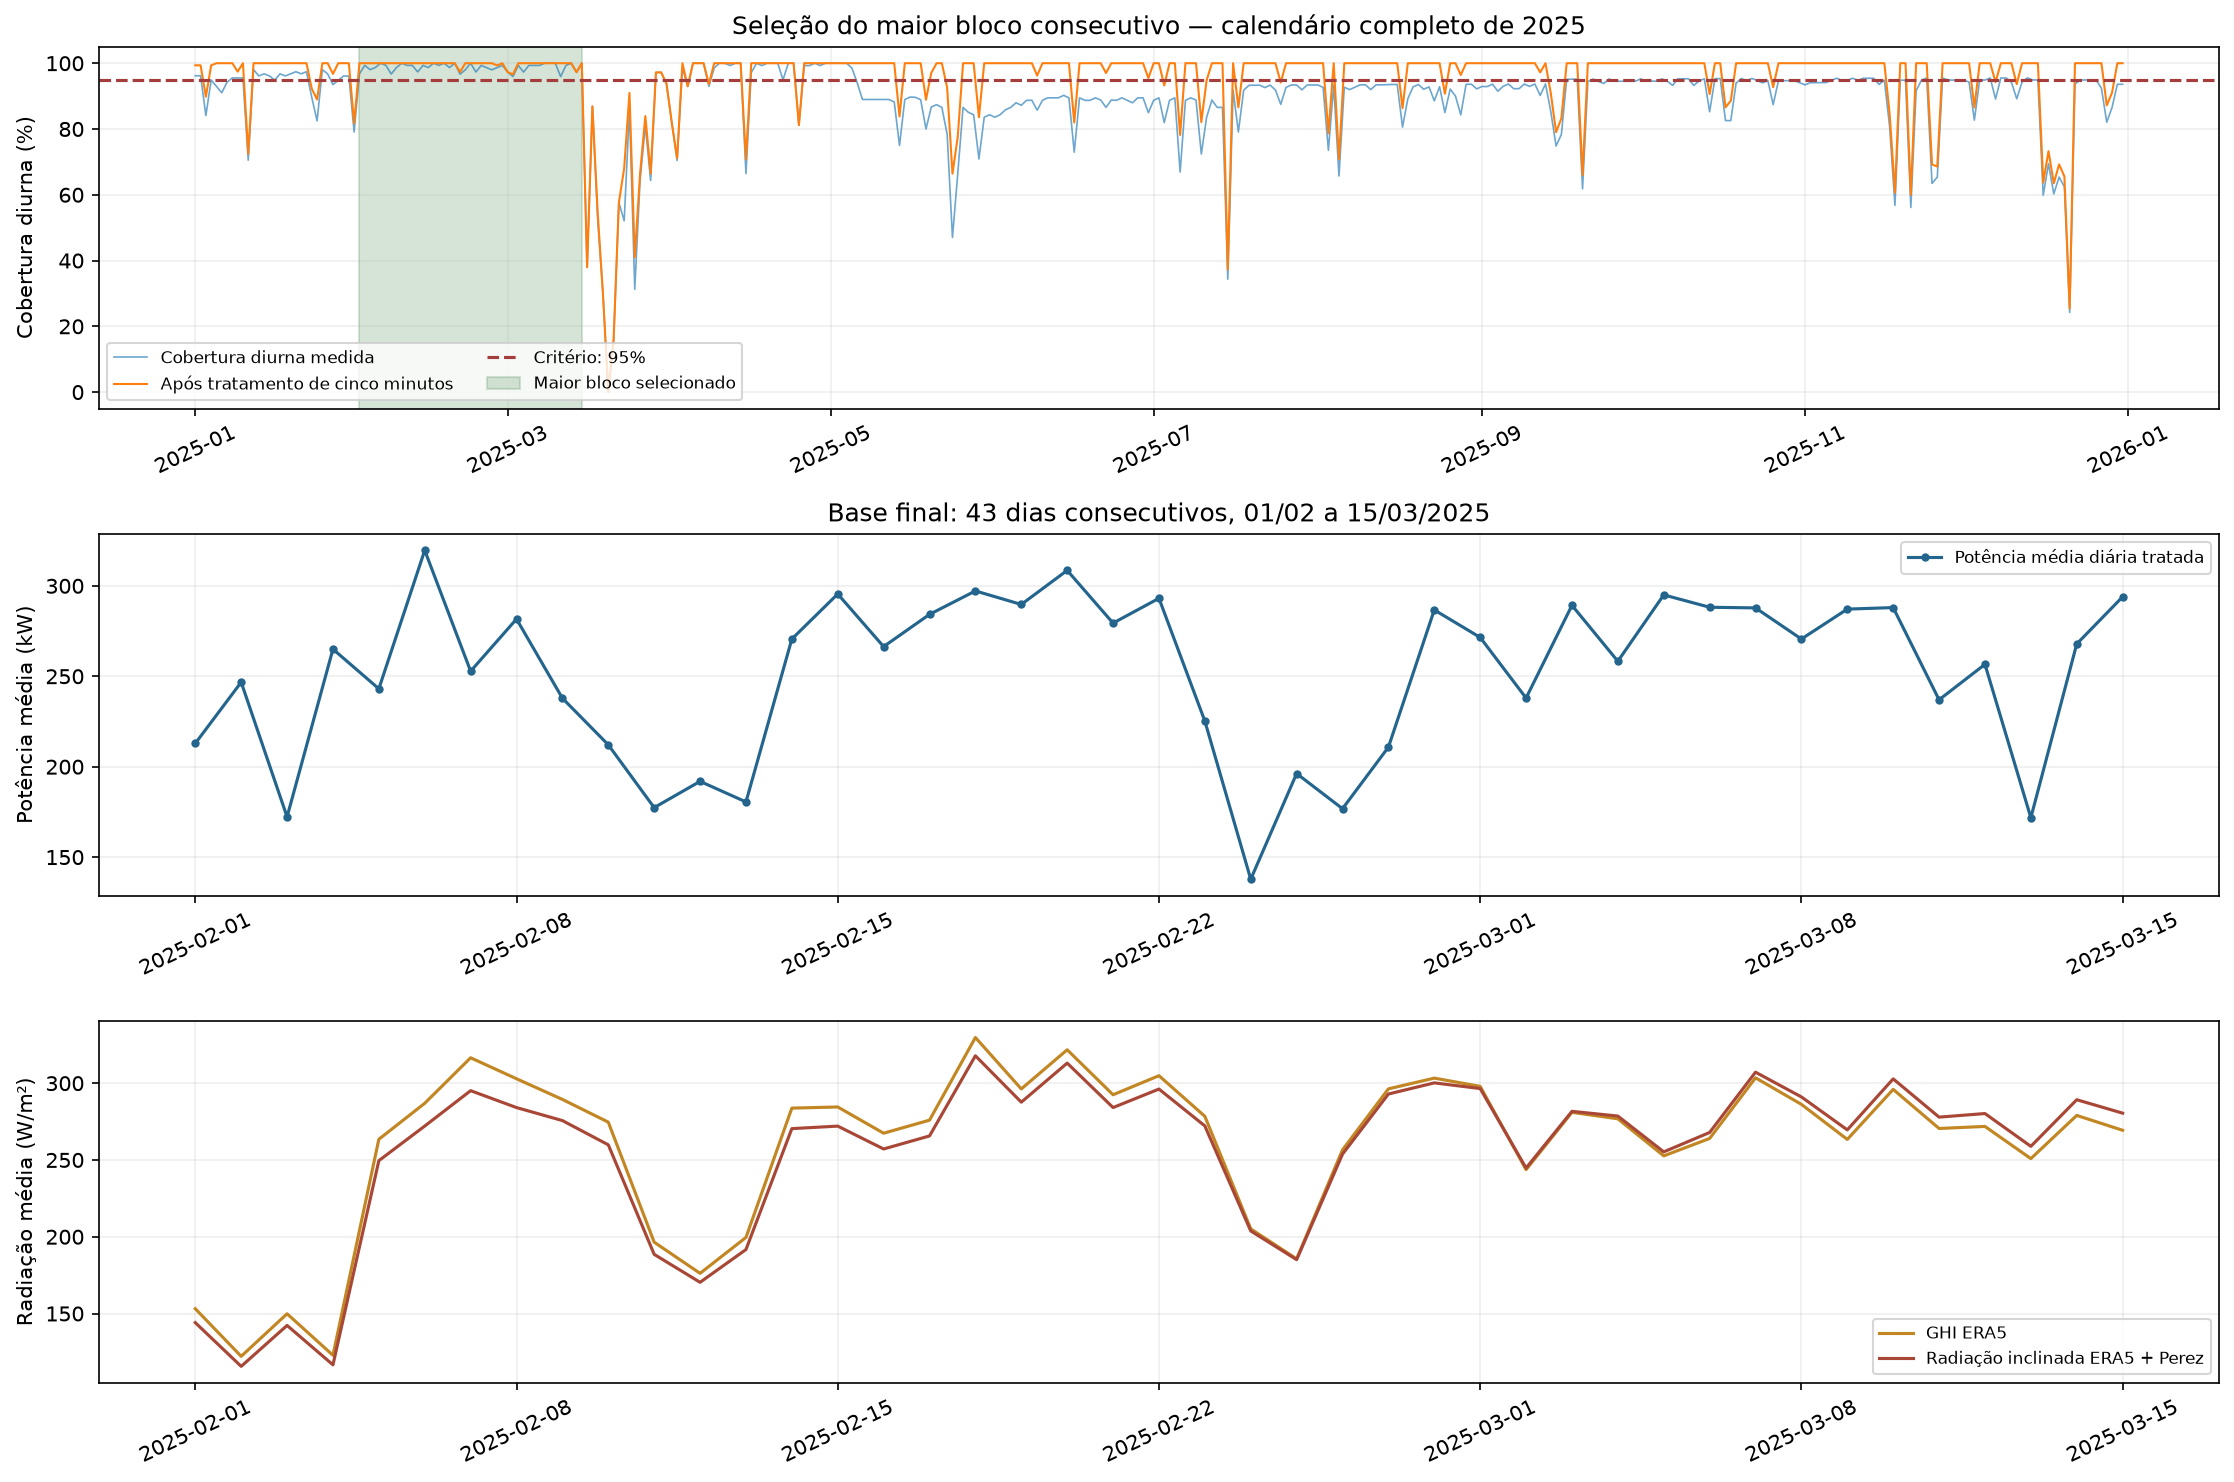

In [21]:
display(df_qualidade_base_final.loc[df_qualidade_base_final.selecionado, [
    "planta_cobertura_diurna_original_pct", "planta_cobertura_diurna_tratada_pct",
    "planta_cobertura_24h_tratada_pct", "planta_diurnos_com_estimativa_pct",
    "leituras_inversor_outros_7_inversores", "leituras_inversor_linear_ate_15min",
    "leituras_inversor_zero_noturno_solar",
]].round(2))
display(Image(filename=str(PASTA_BASE_CONSECUTIVA / "diagnostico_base_consecutiva.png")))


### Uso no experimento

Os 297 dias aprovados no ano estão em `base_diaria_leopoldo_dias_validos.csv`, mas esse arquivo contém saltos de datas: construir janelas dentro de cada bloco, sem atravessar os intervalos excluídos. O arquivo principal contém somente o maior bloco consecutivo, com 43 dias. A quantidade disponível deve orientar o tamanho das janelas e a complexidade do modelo.

A interpolação é retrospectiva e usa o extremo posterior: ao separar treino e teste, refazer o tratamento por partição e não atravessar a fronteira temporal. A estimativa pelos outros sete já calcula a razão somente no passado. Registrar a fração estimada dos alvos usados na avaliação; não usar dias inteiramente reconstruídos como verdade medida. ERA5 é reanálise histórica, não meteorologia prevista em tempo real.

As colunas de corrente contemporânea e contador acumulado de energia não devem entrar automaticamente como preditores da potência do mesmo dia. O contador acumulado não representa energia produzida naquele dia. A geometria inclinada continua usando a hipótese autorizada de 20° e orientação norte.
